# 00 — EDA: hiểu dữ liệu trước khi chọn phương pháp

**Bộ dữ liệu:** [H&M Personalized Fashion Recommendations](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data)

| File | Nội dung | Kích thước |
|---|---|---|
| `customers.csv` | 1.371.980 khách: `age`, `club_member_status`, `fashion_news_frequency`, `Active`, `postal_code` | 207 MB |
| `articles.csv` | 105.542 sản phẩm: tên, loại, nhóm hàng, màu, mô tả | 36 MB |
| `transactions_train.csv` | 31.788.324 giao dịch, 2018-09-20 → 2020-09-22 | 3,5 GB |

**Bài toán:** `age` bị thiếu ở 1,16% khách hàng. Cần điền giá trị đó.

## Vì sao phải EDA trước?

Mô hình chỉ đúng khi hiểu dữ liệu *thực sự* nói gì. Notebook này trả lời 6 câu hỏi, và mỗi câu trả lời
dẫn trực tiếp tới một quyết định thiết kế:

1. Thiếu age có ngẫu nhiên không? → cách báo cáo sai số
2. Phân phối `age` ra sao? → chọn loss + có cần clip
3. Đặc trưng hành vi tương quan với age bao nhiêu? → có dùng được hồi quy tuyến tính không
4. Tín hiệu mạnh nhất nằm ở đâu (article hay địa lý)? → chọn nguồn feature
5. Sai số phụ thuộc gì? → đánh giá đúng nhóm cần điền
6. Đặc trưng nào trùng lặp? → dọn feature

> Notebook này chỉ đọc CSV gốc, **không cần** chạy notebook nào trước.

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Notebook có thể được mở từ thư mục notebooks/ hoặc từ gốc repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

CUSTOMERS = ROOT / "customers.csv"
ARTICLES = ROOT / "articles.csv"
TXN = ROOT / "transactions_train.csv"
ARTIFACTS = ROOT / "artifacts"
OUTPUTS = ROOT / "outputs"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("polars", pl.__version__, "| numpy", np.__version__, "| ROOT =", ROOT)

polars 2.1.0 | numpy 2.3.5 | ROOT = E:\download\age_imputation


## 1. Tổng quan dữ liệu

Ba bảng liên kết qua khoá:

```mermaid
erDiagram
    customers ||--o{ transactions : "customer_id"
    articles  ||--o{ transactions : "article_id"
```

Các cột quan trọng của `customers`:

| Cột | Ý nghĩa | Ghi chú |
|---|---|---|
| `age` | tuổi | **target**, thiếu 1,16% |
| `club_member_status` | trạng thái thành viên | ACTIVE / PRE-CREATE / LEFT CLUB / null |
| `fashion_news_frequency` | tần suất nhận tin | NONE / Regularly / Monthly / null |
| `Active` | có hoạt động trong 30 ngày | 1 hoặc null |
| `postal_code` | mã bưu chính (đã băm) | 352.899 mã khác nhau |

In [2]:
customers = pl.read_csv(CUSTOMERS, schema_overrides={"customer_id": pl.String, "age": pl.Float32})
articles = pl.read_csv(ARTICLES, schema_overrides={"article_id": pl.String})

txn_lf = pl.scan_csv(
    TXN,
    schema_overrides={
        "t_dat": pl.String,
        "customer_id": pl.String,
        "article_id": pl.String,
        "price": pl.Float32,
        "sales_channel_id": pl.Int8,
    },
)

info = txn_lf.select(
    n_txn=pl.len(),
    first_day=pl.col("t_dat").str.to_date("%Y-%m-%d").min(),
    last_day=pl.col("t_dat").str.to_date("%Y-%m-%d").max(),
    n_days=pl.col("t_dat").str.to_date("%Y-%m-%d").n_unique(),
).collect(engine="streaming")

print(f"customers : {customers.height:,} dòng x {customers.width} cột")
print(f"articles  : {articles.height:,} dòng x {articles.width} cột")
info

customers : 1,371,980 dòng x 7 cột
articles  : 105,542 dòng x 25 cột


n_txn,first_day,last_day,n_days
u32,date,date,u32
31788324,2018-09-20,2020-09-22,734


In [3]:
customers.head(3)

customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
str,f64,f64,str,str,f32,str
"""00000dbacae5abe5e23885899a1fa4…",null,null,"""ACTIVE""","""NONE""",49.0,"""52043ee2162cf5aa7ee79974281641…"
"""0000423b00ade91418cceaf3b26c6a…",null,null,"""ACTIVE""","""NONE""",25.0,"""2973abc54daa8a5f8ccfe9362140c6…"
"""000058a12d5b43e67d225668fa1f8d…",null,null,"""ACTIVE""","""NONE""",24.0,"""64f17e6a330a85798e4998f62d0930…"


## 2. Missingness của `age`

Câu hỏi: khách thiếu age có phải là nhóm ngẫu nhiên (MCAR) không? Nếu **không ngẫu nhiên**,
sai số đo trên nhóm có nhãn sẽ **không đại diện** cho nhóm cần điền.

Tỷ lệ thiếu age: 1.16% (15,861 khách)


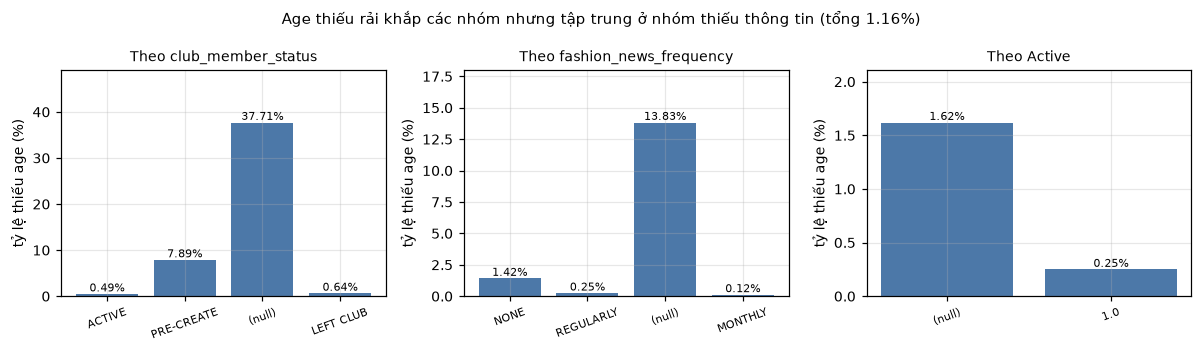

club_member_status,n,miss_rate
str,u32,f64
"""ACTIVE""",1272491,0.004901
"""PRE-CREATE""",92960,0.078916
null,6062,0.377103
"""LEFT CLUB""",467,0.006424


In [4]:
missing_rate = float(customers["age"].is_null().mean())
print(f"Tỷ lệ thiếu age: {missing_rate * 100:.2f}% ({customers['age'].is_null().sum():,} khách)")

aud = customers.with_columns(
    pl.col("age").is_null().alias("missing"),
    pl.col("fashion_news_frequency").str.to_uppercase(),
)


def miss_by(col: str) -> pl.DataFrame:
    return (
        aud.group_by(col)
        .agg(pl.len().alias("n"), pl.col("missing").mean().alias("miss_rate"))
        .sort("n", descending=True)
    )


by_club = miss_by("club_member_status")
by_news = miss_by("fashion_news_frequency")
by_active = miss_by("Active")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, tbl, col, title in [
    (axes[0], by_club, "club_member_status", "Theo club_member_status"),
    (axes[1], by_news, "fashion_news_frequency", "Theo fashion_news_frequency"),
    (axes[2], by_active, "Active", "Theo Active"),
]:
    labels = ["(null)" if v is None else str(v) for v in tbl[col].to_list()]
    rates = (tbl["miss_rate"] * 100).round(2).to_numpy()
    bars = ax.bar(labels, rates, color="#4C78A8")
    ax.bar_label(bars, fmt="%.2f%%", fontsize=7)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel("tỷ lệ thiếu age (%)")
    ax.set_ylim(0, max(rates.max() * 1.3, 1.2))
    ax.tick_params(axis="x", labelrotation=20, labelsize=7)
fig.suptitle(
    f"Age thiếu rải khắp các nhóm nhưng tập trung ở nhóm thiếu thông tin (tổng {missing_rate * 100:.2f}%)",
    fontsize=10,
)
fig.tight_layout()
plt.show()

by_club

**Đọc kết quả:**

- Nhóm `club_member_status` **null**: tới **37,7%** thiếu age, so với **0,49%** ở ACTIVE.
- Nhóm `fashion_news_frequency` null: 13,8%; nhóm không `Active` (không hoạt động 30 ngày qua): 1,62%.
- Tức là khách **càng ít thông tin / ít hoạt động thì càng dễ thiếu age**.

→ Thiếu age mang tính **hệ thống (MNAR)**, không phải MCAR.

**Hệ quả thiết kế:** mô hình học trên nhóm có nhãn (khách "chăm" khai báo hơn), nên MAE đo được là
**cận dưới lạc quan** cho nhóm cần điền. Báo cáo phải nêu rõ điều này (mục 6 và notebook 04).

## 3. Phân phối `age`

Cần biết target liên tục hay rời rạc, có lệch, có outlier — để chọn loss và xử lý biên.

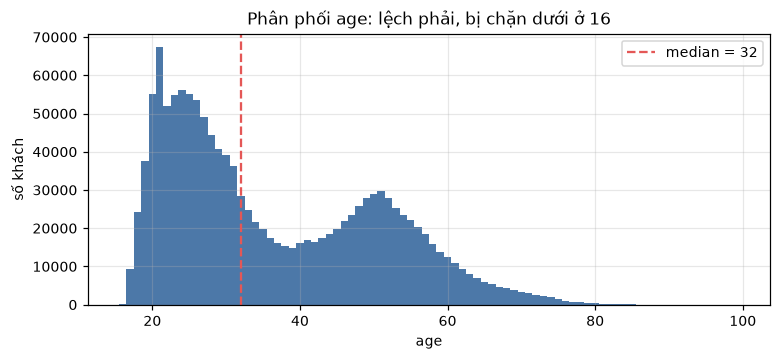

n = 1,356,119 | mean = 36.39 | std = 14.31 | skew = 0.61
phân vị 1/5/25/50/75/95/99: [18. 19. 24. 32. 49. 62. 71.]
khách đúng 16 tuổi: 161 | đúng 99 tuổi: 13
toàn bộ là số nguyên: True


In [5]:
age = customers["age"].drop_nulls().to_numpy()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(age, bins=np.arange(15.5, 100.5, 1), color="#4C78A8")
ax.axvline(np.median(age), color="#E45756", ls="--", label=f"median = {np.median(age):.0f}")
ax.set_xlabel("age")
ax.set_ylabel("số khách")
ax.set_title("Phân phối age: lệch phải, bị chặn dưới ở 16")
ax.legend()
plt.show()

print(
    f"n = {age.size:,} | mean = {age.mean():.2f} | std = {age.std():.2f} "
    f"| skew = {((age - age.mean()) ** 3).mean() / age.std() ** 3:.2f}"
)
print("phân vị 1/5/25/50/75/95/99:", np.percentile(age, [1, 5, 25, 50, 75, 95, 99]).round(0))
print(f"khách đúng 16 tuổi: {(age == 16).sum():,} | đúng 99 tuổi: {(age == 99).sum()}")
print(f"toàn bộ là số nguyên: {bool((age == np.round(age)).all())}")

**Đọc kết quả:**

- Lệch phải (skew ≈ 0,6), đuôi dài tới 99 tuổi, **p99 = 71** → có outlier.
- Chỉ 161 khách đúng 16 tuổi ⇒ không có hiện tượng "dồn cục ở biên" đáng lo, nhưng vẫn cần **clip**.
- Giá trị nguyên ⇒ sai số 1–2 tuổi không phân biệt được về ý nghĩa.

**Hệ quả thiết kế:** dùng **hồi quy** với **loss L1 (MAE)** — bền với outlier và tối ưu đúng metric
quan tâm; **clip dự đoán về [16, 99]**.

## 4. Tín hiệu đơn biến của hành vi mua

Trước khi xây feature cầu kỳ, xem các thống kê hành vi cơ bản tương quan với tuổi bao nhiêu.
Dùng **Spearman** vì nó bền với outlier và đo được quan hệ phi tuyến đơn điệu.

In [6]:
beh = (
    txn_lf.with_columns(
        day=pl.col("t_dat").str.to_date("%Y-%m-%d"),
        weekend=(pl.col("t_dat").str.to_date("%Y-%m-%d").dt.weekday() >= 6),
    )
    .group_by("customer_id")
    .agg(
        pl.len().alias("n_txn"),
        pl.col("price").mean().alias("mean_price"),
        pl.col("price").max().alias("max_price"),
        pl.col("price").std().alias("std_price"),
        pl.col("price").sum().alias("total_spend"),
        pl.col("day").n_unique().alias("n_days"),
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
        (pl.col("sales_channel_id") == 2).cast(pl.Float32).mean().alias("online_share"),
        pl.col("weekend").cast(pl.Float32).mean().alias("weekend_share"),
    )
    .collect(engine="streaming")
    .with_columns(
        (pl.date(2020, 9, 22) - pl.col("last_day")).dt.total_days().alias("recency"),
        (pl.col("last_day") - pl.col("first_day")).dt.total_days().alias("tenure"),
    )
)

prof = (
    customers.select("customer_id", "age")
    .join(beh, on="customer_id", how="inner")
    .drop_nulls("age")
)
print(f"khách có giao dịch và có nhãn: {prof.height:,}")
prof.head(3)

khách có giao dịch và có nhãn: 1,346,520


customer_id,age,n_txn,mean_price,max_price,std_price,total_spend,n_days,first_day,last_day,online_share,weekend_share,recency,tenure
str,f32,u32,f32,f32,f32,f32,u32,date,date,f32,f32,i64,i64
"""00000dbacae5abe5e23885899a1fa4…",49.0,21,0.030904,0.05422,0.015718,0.648983,10,2018-12-27,2020-09-05,0.571429,0.47619,17,618
"""0000423b00ade91418cceaf3b26c6a…",25.0,86,0.030255,0.084729,0.016957,2.601933,23,2018-09-21,2020-07-08,0.94186,0.104651,76,656
"""000058a12d5b43e67d225668fa1f8d…",24.0,18,0.039154,0.06778,0.016858,0.70478,7,2018-09-20,2020-09-15,1.0,0.444444,7,726


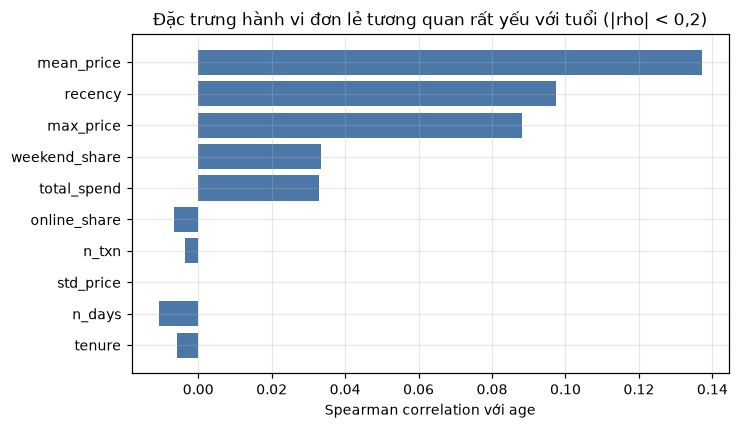

Tương quan mạnh nhất: mean_price = 0.137
  mean_price     +0.137
  recency        +0.097
  max_price      +0.088
  weekend_share  +0.033
  total_spend    +0.033


In [7]:
from scipy.stats import spearmanr

feat_cols = [
    "n_txn", "mean_price", "max_price", "std_price", "total_spend",
    "n_days", "online_share", "weekend_share", "recency", "tenure",
]
sample = prof.sample(n=min(300_000, prof.height), seed=0)
age_s = sample["age"].to_numpy()

rho = {c: float(spearmanr(sample[c].to_numpy(), age_s).statistic) for c in feat_cols}
rho = dict(sorted(rho.items(), key=lambda kv: -abs(kv[1])))

fig, ax = plt.subplots(figsize=(7, 4))
names = list(rho)[::-1]
ax.barh(names, [rho[n] for n in names], color="#4C78A8")
ax.set_xlabel("Spearman correlation với age")
ax.set_title("Đặc trưng hành vi đơn lẻ tương quan rất yếu với tuổi (|rho| < 0,2)")
plt.show()

print("Tương quan mạnh nhất:", f"{list(rho.items())[0][0]} = {list(rho.values())[0]:.3f}")
for k, v in list(rho.items())[:5]:
    print(f"  {k:<14} {v:+.3f}")

**Đọc kết quả:** feature mạnh nhất cũng chỉ |ρ| ≈ 0,15. Mọi thống kê RFM (tần suất, giá trị, gần đây)
gần như **không tuyến tính** với tuổi → hồi quy tuyến tính trên chúng sẽ cho R² ≈ 0.

**Hệ quả thiết kế:** cần (a) mô hình **cây/GBDT** bắt được tương tác phi tuyến, và (b) **nguồn feature khác**
— cụ thể là *khách mua món gì* (mục 5), chứ không phải *mua bao nhiêu*.

## 5. Tín hiệu nằm ở "món gì được mua", không phải "ở đâu"

Ý tưởng: mỗi sản phẩm có "độ tuổi người mua" đặc trưng (đồ baby → phụ huynh ~30–40, menswear → ~38...).
Ta kiểm định hai nguồn tín hiệu bằng một split hold-out công bằng:

- **Train**: 700.000 khách có nhãn (dùng để tính encoding)
- **Eval**: phần còn lại (~656.000 khách) — encoding **không** thấy nhãn của họ

Công thức làm trơn Bayes (α càng lớn càng kéo về prior):

$$\text{enc}(c) = \frac{\sum_{i \in \text{train, mua } c} \text{age}_i + \alpha \cdot \text{prior}}{n_c + \alpha}$$

In [8]:
pairs = txn_lf.select("customer_id", "article_id")
labeled = customers.filter(pl.col("age").is_not_null()).select("customer_id", "age")

rng = np.random.default_rng(42)
perm = rng.permutation(labeled.height)
is_train = np.zeros(labeled.height, dtype=bool)
is_train[perm[:700_000]] = True
labeled = labeled.with_columns(pl.Series("is_train", is_train))

train_ids = labeled.filter(pl.col("is_train")).select("customer_id", "age")
prior = float(train_ids["age"].median())  # prior chỉ lấy từ train
print(f"train = {train_ids.height:,} | eval = {labeled.height - train_ids.height:,} | prior (median) = {prior:.0f}")

ALPHA_ART = 10.0
art_stats = (
    pairs.join(train_ids.lazy(), on="customer_id", how="inner")
    .group_by("article_id")
    .agg(pl.col("age").mean().alias("mean_age"), pl.len().alias("n"))
    .collect(engine="streaming")
    .with_columns(
        ((pl.col("mean_age") * pl.col("n") + prior * ALPHA_ART) / (pl.col("n") + ALPHA_ART)).alias("enc")
    )
)
print(f"sản phẩm có người mua trong train: {art_stats.height:,}")
art_stats.sort("n", descending=True).head(5)

train = 700,000 | eval = 656,119 | prior (median) = 32


sản phẩm có người mua trong train: 100,881


article_id,mean_age,n,enc
str,f32,u32,f64
"""0706016001""",32.310421,25517,32.310299
"""0706016002""",32.99844,17925,32.997883
"""0372860001""",33.762875,16270,33.761792
"""0610776002""",35.354164,15665,35.352024
"""0759871002""",29.838219,13203,29.839855


In [9]:
cust_art = (
    pairs.join(art_stats.lazy().select("article_id", "enc"), on="article_id", how="inner")
    .group_by("customer_id")
    .agg(pl.col("enc").mean().alias("art_te"))
    .collect(engine="streaming")
)

ev = (
    labeled.filter(~pl.col("is_train"))
    .join(cust_art, on="customer_id", how="left")
    .with_columns(pl.col("art_te").fill_null(prior))
)

mae_median = float((ev["age"] - prior).abs().mean())
mae_article = float((ev["art_te"] - ev["age"]).abs().mean())
corr_article = float(np.corrcoef(ev["art_te"], ev["age"])[0, 1])

ALPHA_POSTAL = 50.0
postal_train = (
    labeled.filter(pl.col("is_train"))
    .join(customers.select("customer_id", "postal_code"), on="customer_id")
    .group_by("postal_code")
    .agg(pl.col("age").mean().alias("m"), pl.len().alias("n"))
    .with_columns(
        ((pl.col("m") * pl.col("n") + prior * ALPHA_POSTAL) / (pl.col("n") + ALPHA_POSTAL)).alias("enc")
    )
)
postal_eval = (
    labeled.filter(~pl.col("is_train"))
    .join(customers.select("customer_id", "postal_code"), on="customer_id")
    .join(postal_train.select("postal_code", "enc"), on="postal_code", how="left")
    .with_columns(pl.col("enc").fill_null(prior))
)
mae_postal = float((postal_eval["enc"] - postal_eval["age"]).abs().mean())

print(f"MAE median toàn cục      : {mae_median:.2f} tuổi")
print(f"MAE postal_code encoding : {mae_postal:.2f} tuổi")
print(f"MAE article_id encoding  : {mae_article:.2f} tuổi   | corr với age = {corr_article:.3f}")

MAE median toàn cục      : 12.06 tuổi
MAE postal_code encoding : 12.06 tuổi
MAE article_id encoding  : 11.41 tuổi   | corr với age = 0.469


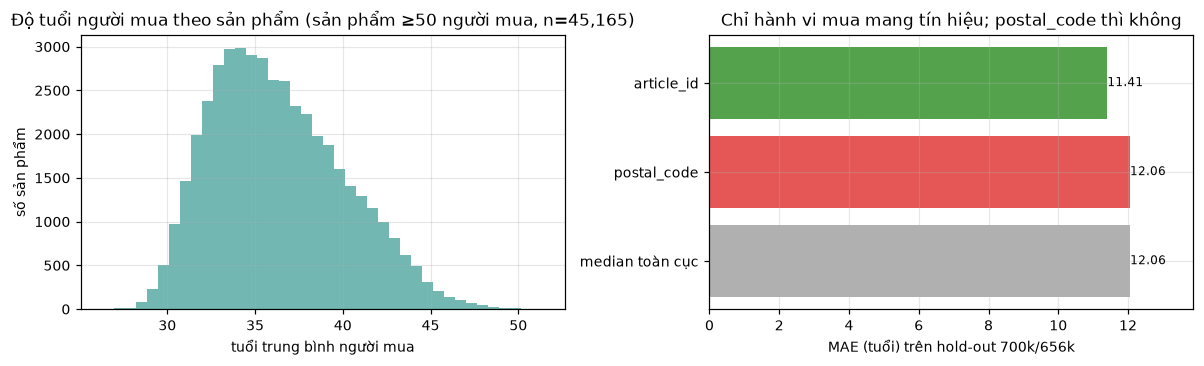

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

ok = art_stats.filter(pl.col("n") >= 50)
axes[0].hist(ok["enc"].to_numpy(), bins=40, color="#72B7B2")
axes[0].set_title(f"Độ tuổi người mua theo sản phẩm (sản phẩm ≥50 người mua, n={ok.height:,})")
axes[0].set_xlabel("tuổi trung bình người mua")
axes[0].set_ylabel("số sản phẩm")

labels = ["median toàn cục", "postal_code", "article_id"]
vals = [mae_median, mae_postal, mae_article]
bars = axes[1].barh(labels, vals, color=["#B0B0B0", "#E45756", "#54A24B"])
axes[1].bar_label(bars, fmt="%.2f", fontsize=8)
axes[1].set_xlim(0, max(vals) * 1.15)
axes[1].set_xlabel("MAE (tuổi) trên hold-out 700k/656k")
axes[1].set_title("Chỉ hành vi mua mang tín hiệu; postal_code thì không")
plt.tight_layout()
plt.show()

**Đọc kết quả:**

| Nguồn | MAE | Nhận xét |
|---|---|---|
| Median toàn cục | ≈ 12,06 | baseline "ngây thơ" |
| `postal_code` encoding | ≈ 12,06 | **không giảm được lỗi** dù phủ 82% khách (2,5 khách/mã) |
| `article_id` encoding | ≈ 11,4 | giảm ~0,7 tuổi; corr với age ≈ 0,49 (gấp 3 lần mọi feature RFM) |

**Hệ quả thiết kế:**

1. **Loại `postal_code`** khỏi feature — chỉ thêm nhiễu.
2. Đầu tư vào **ma trận thưa khách × sản phẩm** và **target encoding nhiều mức**
   (`article_id`, department, product_type, section...), tính **theo từng fold** để tránh rò rỉ.
3. Vẫn giữ tỷ trọng mua theo category (rẻ, bổ trợ, dễ diễn giải).

## 6. Missingness ảnh hưởng thế nào tới sai số?

Ta biết nhóm thiếu age ít hoạt động hơn. Vậy khi điền cho họ, sai số kỳ vọng là bao nhiêu?

In [11]:
prof_all = customers.select("customer_id", "age").join(beh, on="customer_id", how="left")
prof_all = prof_all.with_columns(pl.col("n_txn").fill_null(0))

n_txn = prof_all["n_txn"].to_numpy()
miss = prof_all["age"].is_null().to_numpy()

edges = np.concatenate([[-1], np.percentile(n_txn[~miss], [20, 40, 60, 80, 95]), [np.inf]])
bin_id = np.digitize(n_txn, edges[1:-1])

lab_feat = (
    labeled.filter(pl.col("is_train"))
    .join(cust_art, on="customer_id", how="left")
    .with_columns(pl.col("art_te").fill_null(prior))
    .join(beh.select("customer_id", "n_txn"), on="customer_id", how="left")
    .with_columns(pl.col("n_txn").fill_null(0))
)
lab_bin = np.digitize(lab_feat["n_txn"].to_numpy(), edges[1:-1])
lab_err = (lab_feat["art_te"] - lab_feat["age"]).abs().to_numpy()

rows = []
for b in range(6):
    sel = lab_bin == b
    hi = edges[b + 1]
    rows.append(
        {
            "bin": b + 1,
            "txn_range": f"{max(edges[b], 0):.0f}-{hi:.0f}" if np.isfinite(hi) else f">{edges[b]:.0f}",
            "n_labeled": int(sel.sum()),
            "missing_rate": float(miss[bin_id == b].mean()),
            "missing_share": float((bin_id[miss] == b).mean()),
            "mae_article_te": float(lab_err[sel].mean()),
        }
    )
table = pl.DataFrame(rows)
table

bin,txn_range,n_labeled,missing_rate,missing_share,mae_article_te
i64,str,i64,f64,f64,f64
1,"""0-3""",135677,0.021325,0.3612,12.69553
2,"""3-6""",123248,0.016332,0.249606,11.755825
3,"""6-14""",154398,0.011293,0.215434,11.273337
4,"""14-34""",145031,0.006905,0.123132,11.019118
5,"""34-91""",106308,0.003467,0.045268,10.42251
6,""">91""",35338,0.001243,0.005359,9.630174


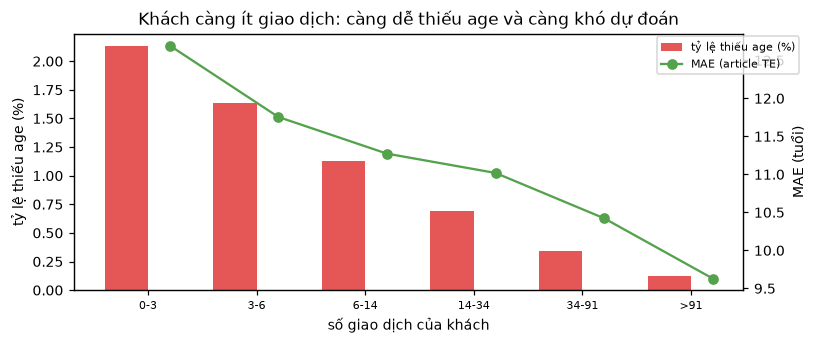

Cơ cấu nhóm thiếu theo mức hoạt động (%): [36.1 25.  21.5 12.3  4.5  0.5]
MAE kỳ vọng trên nhóm thiếu (với article TE) ≈ 11.83 tuổi


In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = np.arange(table.height)
ax.bar(xs - 0.2, table["missing_rate"].to_numpy() * 100, width=0.4, color="#E45756", label="tỷ lệ thiếu age (%)")
ax2 = ax.twinx()
ax2.plot(xs + 0.2, table["mae_article_te"].to_numpy(), "o-", color="#54A24B", label="MAE (article TE)")
ax.set_xticks(xs)
ax.set_xticklabels(table["txn_range"].to_list(), fontsize=7)
ax.set_xlabel("số giao dịch của khách")
ax.set_ylabel("tỷ lệ thiếu age (%)")
ax2.set_ylabel("MAE (tuổi)")
ax.set_title("Khách càng ít giao dịch: càng dễ thiếu age và càng khó dự đoán")
ax.grid(False)
ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.98, 0.9), fontsize=7)
plt.tight_layout()
plt.show()

expected = float(np.sum(table["missing_share"].to_numpy() * table["mae_article_te"].to_numpy()))
print(f"Cơ cấu nhóm thiếu theo mức hoạt động (%): {np.round(table['missing_share'].to_numpy() * 100, 1)}")
print(f"MAE kỳ vọng trên nhóm thiếu (với article TE) ≈ {expected:.2f} tuổi")

**Đọc kết quả:**

- Tỷ lệ thiếu giảm từ ~2,1% (khách 0–3 giao dịch) xuống ~0,12% (khách > 91 giao dịch).
- 36% khách thiếu age nằm ở nhóm **ít hoạt động nhất**; chỉ 0,5% ở nhóm hoạt động mạnh.
- MAE tăng gần gấp đôi khi khách ít dữ liệu hành vi (≈6 tuổi → ≈11 tuổi).

**Hệ quả thiết kế:** trộn sai số theo cơ cấu hoạt động của nhóm thiếu để báo cáo **MAE kỳ vọng trên nhóm
cần điền** (với mô hình cuối là ≈9,7 tuổi — notebook 04), thay vì quảng bá MAE 8,8 trên nhóm có nhãn.

## 7. Chất lượng & trùng lặp đặc trưng

Kiểm tra nhanh các cột có nguy cơ trùng thông tin (để tránh phình số chiều vô ích).

In [13]:
from scipy.stats import spearmanr

beh_pairs = [
    ("total_spend", "log_total_spend"),
    ("n_txn", "total_spend"),
    ("n_txn", "n_txn_365d"),
    ("Active", "active_flag"),
    ("mean_price", "median_price"),
    ("postal_size", "log_postal_size"),
]
print("Các cặp feature đáng kiểm tra:")
for a, b in beh_pairs:
    if a in prof.columns and b in prof.columns:
        x, z = prof[a].to_numpy().astype(float), prof[b].to_numpy().astype(float)
        good = np.isfinite(x) & np.isfinite(z)
        print(f"  {a:<14} ~ {b:<16} rho = {spearmanr(x[good], z[good]).statistic:+.3f}")
    else:
        print(f"  {a:<14} ~ {b:<16} (sẽ kiểm tra trong notebook 02/04)")

Các cặp feature đáng kiểm tra:
  total_spend    ~ log_total_spend  (sẽ kiểm tra trong notebook 02/04)


  n_txn          ~ total_spend      rho = +0.960
  n_txn          ~ n_txn_365d       (sẽ kiểm tra trong notebook 02/04)
  Active         ~ active_flag      (sẽ kiểm tra trong notebook 02/04)
  mean_price     ~ median_price     (sẽ kiểm tra trong notebook 02/04)
  postal_size    ~ log_postal_size  (sẽ kiểm tra trong notebook 02/04)


**Kết luận:** `Active` và `active_flag` là một cột bị nhân đôi; `total_spend` và `log_total_spend`
trùng thông tin (ρ = 1). Với **GBDT**, biến đổi đơn điệu không làm thay đổi kết quả chia nhánh,
nên các cột này không gây hại — chỉ tăng nhẹ số chiều. Ghi chú để người đọc biết, không cần xử lý.

## 8. Bảng quyết định: EDA → phương pháp

| Phát hiện | Số liệu | Quyết định kéo theo |
|---|---|---|
| Thiếu age **không ngẫu nhiên** | 37,7% ở nhóm `club_member_status` null vs 0,49% ACTIVE; median giao dịch 4 vs 9 | Báo cáo thêm MAE kỳ vọng trên nhóm thiếu |
| Target lệch phải, đuôi dài | skew ≈ 0,6; p99 = 71 | Hồi quy + **loss L1** + clip [16, 99] |
| RFM đơn biến rất yếu | max \|ρ\| ≈ 0,15 | Không dùng linear/mean imputation → **GBDT** |
| Nhóm hàng tách tuổi tốt | Baby/Children vs Divided lệch ~8 tuổi | Thêm tỷ trọng mua theo category |
| Tín hiệu ở **article** | MAE 11,3 vs 12,1; corr 0,49 | **Ma trận cust × article** + target encoding nhiều mức |
| `postal_code` vô tín hiệu | MAE ≈ median | **Loại** khỏi feature |
| Sai số phụ thuộc mức hoạt động | 6 tuổi (>91 txn) → 11 tuổi (≤3 txn) | Báo cáo MAE theo nhóm + MAE kỳ vọng |
| 31,8M giao dịch, RAM hạn chế | 3,5 GB CSV | **Polars streaming** → Parquet gọn, float32 + memmap |

➡️ Tiếp theo: **01_prepare_data.ipynb** — chuẩn hoá dữ liệu theo các quyết định trên.